# Proyecto Oráculo

Análisis y Diseño de Algoritmos

El trabajo es encontrar una **configuración de prompt** — un índice por ranura del catálogo, más la temperatura — que haga que el modelo cumpla restricciones verificables. Ustedes solo escriben en la **celda 4**. Todo lo demás ya está hecho.

El oráculo es una caja negra: le dan una config y un lote de instancias, y les devuelve la precisión y las trazas de lo que falló. Pueden consultar `evaluar` y `validar` cuantas veces quieran; lo ya generado no se vuelve a calcular.

```
r = oraculo.evaluar(config, instancias, semilla)
r_val = oraculo.validar(config, n)   # partición de validación, muestra fija

r.precision        # 0.55
r.trazas           # [{id, violo, salida}, ...]
```

Cada instancia trae **hasta 5 restricciones** y se puntúa todo-o-nada: falla una, vale 0. Midan cada candidata sobre las mismas 100 instancias de `busqueda`: con menos, los pasos cerca del piso se confunden con cero.

Cada ranura ofrece un consejo de prompting distinto, y algunos combinan mal con las restricciones que mide el verificador. Las trazas dicen qué restricción falló. Guarden cada `r.precision` y dibujen `curva(historial)`.

`espacio()` tiene **32 768** configs con temperatura 0.0 — ocho opciones por ranura, cinco ranuras. `espacio(TEMPERATURAS)` agrega 0.3 y 0.7 y lo triplica. Sortear no alcanza: hay una sola opción limpia por ranura, y acertar cuatro de cinco al azar pasa 1 vez cada 900.


## 1 · Instalar y bajar los 3 archivos  ·  *al terminar, reinicia el entorno de ejecución*

Baja `oraculo.py`, `ayudas.py` y `datos_visibles.json`, más las librerías que usan el modelo y los verificadores. El reinicio es obligatorio: si siguen sin reiniciar, `transformers` a veces queda a medias y `cargar_modelo` falla con un error opaco.


In [1]:
# bitsandbytes: checkpoints 4-bit (qwen8b, mistral7b). nltk/spacy/emoji/langdetect:
# los usa el verificador de open-instruct, no el notebook.
!pip install -q -U "bitsandbytes>=0.46.1" transformers accelerate \
                   nltk spacy emoji langdetect immutabledict
!python -m spacy download en_core_web_sm -q
!git clone -q https://github.com/allenai/open-instruct

REPO = "https://raw.githubusercontent.com/DanielMelo404/Proyecto-Oraculo-AyD/main"
# --no-cache: Colab a veces reusa un ayudas.py viejo y el alias no existe.
!wget -q --no-cache -O oraculo.py {REPO}/oraculo.py
!wget -q --no-cache -O ayudas.py {REPO}/ayudas.py
!wget -q --no-cache -O datos_visibles.json {REPO}/datos_visibles.json

# Los datos de nltk se bajan a mano: su downloader rechaza el proxy de Colab.
import io
import urllib.request
import zipfile

NLTK_DATA = "https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/packages"
PAQUETES = [
    ("tokenizers", "punkt"),
    ("tokenizers", "punkt_tab"),
    ("taggers", "averaged_perceptron_tagger"),
    ("taggers", "averaged_perceptron_tagger_eng"),
]
for carpeta, nombre in PAQUETES:
    with urllib.request.urlopen(f"{NLTK_DATA}/{carpeta}/{nombre}.zip") as resp:
        zipfile.ZipFile(io.BytesIO(resp.read())).extractall(f"/root/nltk_data/{carpeta}")

print("LISTO  →  Entorno de ejecución ▸ Reiniciar sesión, y sigue en la celda 2")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
LISTO  →  Entorno de ejecución ▸ Reiniciar sesión, y sigue en la celda 2


## 2 · El modelo

Antes: **Entorno de ejecución ▸ Cambiar tipo de entorno de ejecución ▸ T4 GPU**.
Sin GPU, `cargar_modelo` no arranca.

`cargar_modelo` acepta un alias de la tabla o cualquier id público de Hugging Face (`org/nombre`). En `ayudas.py` hay más alias (`qwen8b`, `mistral7b`): caben en T4 en 4-bit, pero cada consulta tarda más.

| Alias | Checkpoint | Tamaño | Notas |
|---|---|---|---|
| `qwen17b` | `Qwen/Qwen3-1.7B` | 1.7B | el de por defecto; el más rápido |
| `ministral3b` | `mistralai/Ministral-3-3B-Instruct-2512-BF16` | 3.8B | fp16, ~7.7 GB de VRAM |
| `llama3b` | `unsloth/Llama-3.2-3B-Instruct` | 3.2B | fp16, ~6.4 GB de VRAM |

Son tres familias distintas (Qwen, Mistral, Llama): sirve para ver si su configuración generaliza o si solo le funciona a un modelo.

El caché guarda el nombre del modelo en la clave, así que cambiar de modelo **no** reusa respuestas del anterior: vuelve a gastar rollouts.

> Usen el repo `-BF16` de Ministral 3. El repo por defecto es FP8 y la T4 no lo soporta.


In [1]:
from ayudas import cargar_modelo

# Alias → checkpoint. El nombre entra en la clave de caché: si cambian de
# modelo, las respuestas anteriores no se reusan.
#  "qwen17b"     → Qwen/Qwen3-1.7B
#  "ministral3b" → mistralai/Ministral-3-3B-Instruct-2512-BF16
#  "llama3b"     → unsloth/Llama-3.2-3B-Instruct
modelo = cargar_modelo("qwen17b")


cargando qwen17b → Qwen/Qwen3-1.7B


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

... (3 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Qwen/Qwen3-1.7B  VRAM: 3.44 GB


## 3 · El oráculo

`dividir` parte `datos_visibles.json` en búsqueda (150) y validación (300). Busquen solo sobre `busqueda`. `validar` mide la config ya elegida sobre instancias que no se usaron al buscar: sirve para ver si generaliza a **instancias** nuevas, no a tipos de restricción nuevos.

Si Colab se desconecta, descomenten las dos líneas de Drive para no perder el caché.


In [2]:
# Descomenten estas dos líneas si quieren que el caché sobreviva a una
# desconexión: el path de Drive reemplaza cache_oraculo.json local.
from google.colab import drive
drive.mount("/content/drive")

from oraculo import Oraculo, CATALOGO, espacio
from ayudas import cargar_datos, dividir

datos = cargar_datos()
busqueda, validacion = dividir(datos)
# 1.7B en fp16 deja VRAM en la T4: un lote más grande genera más prompts a la vez.
oraculo = Oraculo(modelo, busqueda, validacion, lote=16, presupuesto=32_000_000)
# oraculo = Oraculo(modelo, busqueda, validacion, cache="/content/drive/MyDrive/oraculo_cache.json", lote=16, presupuesto=32_000_000)

# 32768 configs (temperatura 0.0). Para incluir 0.3 y 0.7: espacio(TEMPERATURAS)
CONFIGS = espacio()
print(len(CONFIGS), "configuraciones posibles")


Mounted at /content/drive
450 instancias, 2.3 restricciones por instancia
búsqueda: 100 inst, 2.5 restr/inst
validación: 87 inst, 2.4 restr/inst
(263 instancias descartadas: no medían nada — ver `dividir`)
modo pensamiento: apagado
32768 configuraciones posibles


## 4 · Aquí escriben ustedes

Abajo hay una **búsqueda aleatoria** de ejemplo: saca configuraciones al azar del
espacio y se queda con la mejor. Está para que vean cómo se consulta el oráculo
y cómo se arma `curva(historial)`, no para imitarla.

Bórrenla y pongan su heurística. Dejen definidas `mejor` e `INSTANCIAS`: las celdas de
abajo (fallos, validación, entrega) las usan.


eval   1 |  5.0% | (del registro)
eval   2 |  7.0% | (del registro)
eval   3 |  6.0% | (del registro)
eval   4 |  7.0% | (del registro)
eval   5 |  7.0% | (del registro)
eval   6 |  6.0% | (del registro)
eval   7 |  8.0% | (del registro)
eval   8 |  5.0% | (del registro)
>>> pasada 1 | rol -> 5 |  8.0%
eval   9 |  4.0% | (del registro)
eval  10 |  6.0% | (del registro)
eval  11 |  4.0% | (del registro)
eval  12 |  5.0% | (del registro)
eval  13 |  6.0% | (del registro)
eval  14 |  5.0% | (del registro)
eval  15 |  5.0% | (del registro)
>>> pasada 1 | estrategia -> 1 |  8.0%
eval  16 | 11.0% | (del registro)
eval  17 |  7.0% | (del registro)
eval  18 |  6.0% | (del registro)
eval  19 | 12.0% | (del registro)
eval  20 |  5.0% | (del registro)
eval  21 |  8.0% | (del registro)
eval  22 |  6.0% | (del registro)
>>> pasada 1 | formato -> 4 | 12.0%
eval  23 |  9.0% | (del registro)
eval  24 |  8.0% | (del registro)
eval  25 | 11.0% | (del registro)
eval  26 |  9.0% | (del registro)
eval  27 

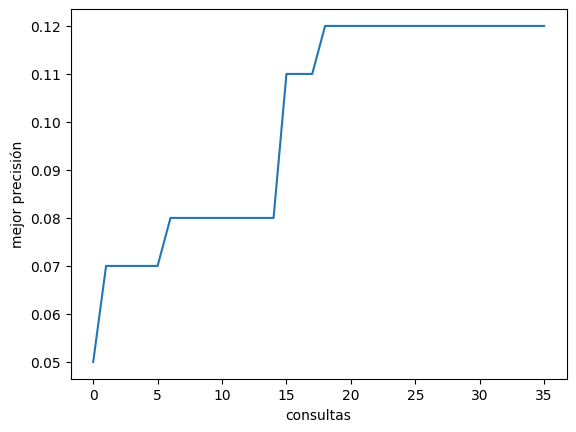

In [6]:
import random, time, json, os
from ayudas import curva

random.seed(0)

SLOTS = ["rol", "estrategia", "formato", "estilo", "cierre"]
INSTANCIAS = busqueda
RUTA_REGISTRO = "/content/drive/MyDrive/registro_busqueda_final.json"

# incluyo esto debido a que el resultado de la celda se me había borrado, pero lo
# tenía descargado en un archivo .json
registro = json.load(open(RUTA_REGISTRO)) if os.path.exists(RUTA_REGISTRO) else []

def clave(c):
    return tuple(c[s] for s in SLOTS) + (c["temperatura"],)

vistos = {clave(r["config"]): r["precision"] for r in registro}

def evaluar_y_registrar(cfg, historial, semilla):
    k = clave(cfg)
    if k in vistos:                                   # ya evaluada: no gasta GPU
        historial.append(vistos[k])
        print(f"eval {len(historial):3d} | {vistos[k]:5.1%} | (del registro)")
        return vistos[k]
    t0 = time.time()
    p = oraculo.evaluar(cfg, INSTANCIAS, semilla=semilla).precision
    dt = time.time() - t0
    vistos[k] = p
    historial.append(p)
    registro.append({"config": dict(cfg), "precision": p, "segundos": round(dt, 1)})
    json.dump(registro, open(RUTA_REGISTRO, "w"), indent=1)
    print(f"eval {len(historial):3d} | {p:5.1%} | {dt:6.1f}s")
    return p

def descenso_coordenadas(inicial, max_pasadas=1, semilla=1):
    actual = dict(inicial)
    historial = []
    p_actual = evaluar_y_registrar(actual, historial, semilla)
    for pasada in range(max_pasadas):
        hubo_mejora = False
        for slot in SLOTS:
            mejor_op, mejor_p = actual[slot], p_actual
            for op in range(8):
                if op == actual[slot]:
                    continue
                p = evaluar_y_registrar({**actual, slot: op}, historial, semilla)
                if p > mejor_p:
                    mejor_op, mejor_p = op, p
            if mejor_op != actual[slot]:
                actual[slot], p_actual, hubo_mejora = mejor_op, mejor_p, True
            print(f">>> pasada {pasada+1} | {slot} -> {actual[slot]} | {p_actual:5.1%}")
        if not hubo_mejora:
            break
    return actual, p_actual, historial

# en caso de que ya haya un archivo con el registro, forma un diccionario con él, si no,
# realiza las 36 evaluaciones desde 0 usando GPU.
inicial = dict(registro[0]["config"]) if registro else random.choice(CONFIGS)
cfg, prec, historial = descenso_coordenadas(inicial, max_pasadas=1)

# guardamos la mejor configuración, que se utilizará más adelante
mejor = (prec, cfg)
print("\nmejor configuración:", mejor[1])
curva(historial)

In [7]:
import pandas as pd

tabla = pd.DataFrame([
    {**r["config"], "precision": r["precision"], "segundos": r["segundos"]}
    for r in registro
])
display(tabla.style.format({"precision": "{:.0%}"}).highlight_max(subset="precision", color="lightgreen"))

print("evaluaciones:", len(tabla))
print("tiempo medio por evaluación:", round(tabla.segundos.mean(), 1), "s")
print("tiempo total:", round(tabla.segundos.sum() / 60, 1), "min")
print(f"precisión inicial: {tabla.precision.iloc[0]:.0%}  ->  mejor: {tabla.precision.max():.0%}")

,rol,estrategia,formato,estilo,cierre,temperatura,precision,segundos
0,6,1,2,3,7,0.000000,5%,180.600000
1,0,1,2,3,7,0.000000,7%,203.100000
2,1,1,2,3,7,0.000000,6%,202.500000
3,2,1,2,3,7,0.000000,7%,217.500000
4,3,1,2,3,7,0.000000,7%,217.400000
5,4,1,2,3,7,0.000000,6%,217.300000
6,5,1,2,3,7,0.000000,8%,217.000000
7,7,1,2,3,7,0.000000,5%,216.200000
8,5,0,2,3,7,0.000000,4%,219.800000
9,5,2,2,3,7,0.000000,6%,216.300000


evaluaciones: 36
tiempo medio por evaluación: 215.3 s
tiempo total: 129.2 min
precisión inicial: 5%  ->  mejor: 12%


### Leer los fallos

Cada resultado trae sus trazas: mírenlas todas las veces que quieran. `violo` es la **primera** restricción que no pasó (el puntaje es todo-o-nada, no hace falta listar las demás). `salida` es el texto que produjo el modelo.

Si quieren ver el prompt **antes** de generar, `ver_prompt(config, instancia)` en `ayudas` arma el texto exacto que recibiría el modelo.


In [8]:
# Reusa el caché: estas instancias ya se midieron al buscar.
r = oraculo.evaluar(mejor[1], INSTANCIAS, semilla=1)

for t in r.trazas[:3]:
    print("violó:", t["violo"])
    print(t["salida"][:300])
    print("-" * 60)


evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

violó: letters:letter_counting2
<<A Question About My Name>>

My name is A. I am a meticulous assistant. I follow every formatting requirement exactly, and I add nothing the request did not ask for. I write out at least three candidate answers in full, then say which one I picked and why. I split every reply into at least four sho
------------------------------------------------------------
violó: punctuation:punctuation_dot
```python
def analyze_project_progress(projects):
    # Calculate the average completion percentage of all projects
    total_completion = 0
    count_projects = 0
    for project in projects:
        total_completion += project['completion']
        count_projects += 1
    if count_projects > 0:
  
------------------------------------------------------------
violó: punctuation:punctuation_dot
"  
The mysterious and enigmatic stranger, known for sharing their most heart-wrenching and passionate love story, traveled from city to city, leaving behind tales of romance

### Validar la config elegida

Las 300 instancias de validación no se usaron al buscar. Sirve para ver si la config aguanta instancias nuevas, no para elegir otra — si eligen con la validación, dejan de ser un conjunto de prueba.

Validarlas todas tarda; `n` escoge cuántas medir. La muestra es fija: las mismas n en cada llamada. Además imprime qué restricciones se cayeron más.


In [9]:
# Validamos con todas las instancias posibles. En esta ocasión, son 87
r_val = oraculo.validar(mejor[1], n=None)

print("búsqueda (mejor):", f"{mejor[0]:.1%}")
print("validación:      ", f"{r_val.precision:.1%}")


validando:   0%|          | 0/87 [00:00<?, ?inst/s]

validación: 10.3%  (87 inst)
    6  last_word:last_word_sent
    5  letters:letter_counting
    5  copy:repeat_phrase
    4  first_word:first_word_sent
    4  last_word:last_word_answer
    4  detectable_format:multiple_sections
    4  combination:repeat_prompt
    4  keywords:word_once
búsqueda (mejor): 12.0%
validación:       10.3%


## 5 · La entrega

Un `entrega.json` con el grupo, la config ganadora y la semana. La config lleva un índice por ranura (`rol`, `estrategia`, `formato`, `estilo`, `cierre`) y `temperatura`. La nota no sale de este notebook: el profesor corre esa config sobre un test privado. Cambien `G07` y `semana` antes de descargar.


In [10]:
from ayudas import entrega
from google.colab import files

# grupo: identificador del equipo. semana: número de semana del curso.
entrega(grupo="G07", config=mejor[1], semana=6)
files.download("entrega.json")


{
 "grupo": "G07",
 "config": {
  "rol": 5,
  "estrategia": 1,
  "formato": 4,
  "estilo": 3,
  "cierre": 7,
  "temperatura": 0.0
 },
 "semana": 6
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>